In [3]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Celda 1 — Verificación de entorno
# Si Ultralytics no está instalado, ejecutar antes: !pip install ultralytics opencvpython-headless
import sys
import torch
import ultralytics

print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"Ultralytics: {ultralytics.__version__}")
print(f"GPU disponible: {torch.cuda.is_available()}")

dispositivo = 0 if torch.cuda.is_available() else "cpu"
print(f"Dispositivo a usar: {dispositivo}")

Python: 3.14.6
PyTorch: 2.14.1+cpu
Ultralytics: 8.4.178
GPU disponible: False
Dispositivo a usar: cpu


In [4]:
# Celda 2 — Cargar el modelo y detectar objetos en una imagen de ejemplo
from ultralytics import YOLO

modelo = YOLO("yolo11n.pt") # descarga ~5 MB la primera vez
resultados = modelo("https://ultralytics.com/images/bus.jpg", device=dispositivo) 
#también guarda bus.jpg en la carpeta actual
r = resultados[0]

print(f"Tamaño de la imagen original: {r.orig_shape}") # (alto, ancho)
for caja in r.boxes:
    clase = modelo.names[int(caja.cls)]
    x1, y1, x2, y2 = caja.xyxy[0].tolist()
    print(f"{clase:<7} conf={float(caja.conf):.2f} caja=({x1:.0f}, {y1:.0f}, {x2:.0f}, {y2:.0f})")



Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 c:\Users\Rog Strix\OneDrive\Documentos\Universidad\IA\TrabajosFIA\bus.jpg: 640x480 4 persons, 1 bus, 65.0ms
Speed: 1.8ms preprocess, 65.0ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)
Tamaño de la imagen original: (1080, 810)
bus     conf=0.94 caja=(4, 229, 796, 728)
person  conf=0.89 caja=(671, 395, 810, 879)
person  conf=0.88 caja=(47, 400, 239, 904)
person  conf=0.86 caja=(223, 409, 344, 860)
person  conf=0.62 caja=(0, 556, 69, 872)


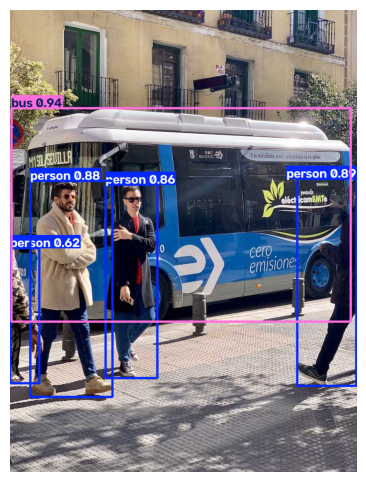

In [5]:
# Celda 3 — Visualizar
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 6))
plt.imshow(r.plot()[..., ::-1]) 
# r.plot() devuelve la imagen anotada en formato
# BGR; se invierte a RGB
plt.axis("off")
plt.show()

In [6]:
# Celda 4 — Función IoU y carga de cajas reales de COCO8
from pathlib import Path
import cv2
import numpy as np
from ultralytics.data.utils import check_det_dataset

def iou(a, b):
 x1, y1 = max(a[0], b[0]), max(a[1], b[1])
 x2, y2 = min(a[2], b[2]), min(a[3], b[3])
 inter = max(0, x2 - x1) * max(0, y2 - y1)
 union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
 return inter / union if union > 0 else 0.0

info = check_det_dataset("coco8.yaml") # descarga COCO8 la primera vez (~1MB)

carpeta_val = Path(info["val"])
print("Imágenes de validación:", len(list(carpeta_val.glob("*.jpg"))))

def cargar_reales(ruta_img):
 """Lee las etiquetas de YOLO (clase cx cy w h, normalizadas) y las pasa a (clase,
(x1, y1, x2, y2)) en píxeles."""
 ruta_lbl = Path(str(ruta_img).replace("images", "labels")).with_suffix(".txt")
 alto, ancho = cv2.imread(str(ruta_img)).shape[:2]
 reales = []
 for linea in ruta_lbl.read_text().splitlines():
    c, cx, cy, w, h = linea.split()
    cx, cy, w, h = float(cx) * ancho, float(cy) * alto, float(w) * ancho, float(h) * alto
    reales.append((int(c), (cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2)))
    return reales

Imágenes de validación: 4


In [7]:
#  Celda 5 — Emparejar detecciones con cajas reales (umbral de IoU = 0.5, confianza
mínima = (0.25)
tp = fp = fn = 0
for ruta in sorted(carpeta_val.glob("*.jpg")):
 reales = cargar_reales(ruta)
 r = modelo(str(ruta), conf=0.25, verbose=False, device=dispositivo)[0]
 preds = sorted([(float(b.conf), int(b.cls), b.xyxy[0].tolist()) for b in r.boxes],
reverse=True)
 usados = set() # cajas reales ya emparejadas: cada una solo puede emparejarse una vez
 tp_i = 0
 for conf, cls, caja in preds: # de mayor a menor confianza
    mejor, mejor_iou = None, 0.0
    for k, (clase_real, caja_real) in enumerate(reales):
        if clase_real == cls and k not in usados:
            v = iou(caja, caja_real)
            if v > mejor_iou:
                mejor, mejor_iou = k, v
 if mejor is not None and mejor_iou >= 0.5:
    usados.add(mejor)
 tp_i += 1
 fp_i, fn_i = len(preds) - tp_i, len(reales) - tp_i
 tp, fp, fn = tp + tp_i, fp + fp_i, fn + fn_i
 print(f"{ruta.name}: reales={len(reales)} detecciones={len(preds)} TP={tp_i} FP={fp_i} FN={fn_i}")
 print(f"TOTAL: TP={tp} FP={fp} FN={fn} | precisión={tp/(tp+fp):.3f} recall={tp/(tp+fn):.3f}")


000000000036.jpg: reales=1 detecciones=2 TP=1 FP=1 FN=0
TOTAL: TP=1 FP=1 FN=0 | precisión=0.500 recall=1.000
000000000042.jpg: reales=1 detecciones=2 TP=1 FP=1 FN=0
TOTAL: TP=2 FP=2 FN=0 | precisión=0.500 recall=1.000
000000000049.jpg: reales=1 detecciones=8 TP=1 FP=7 FN=0
TOTAL: TP=3 FP=9 FN=0 | precisión=0.250 recall=1.000
000000000061.jpg: reales=1 detecciones=2 TP=1 FP=1 FN=0
TOTAL: TP=4 FP=10 FN=0 | precisión=0.286 recall=1.000


In [8]:
# Celda 6 — Comparar con la evaluación automática de Ultralytics
metricas = modelo.val(data="coco8.yaml", plots=False, verbose=False,
device=dispositivo)
print(f"mAP50 = {metricas.box.map50:.3f}")
print(f"mAP50-95 = {metricas.box.map:.3f}")
print(f"Precisión media = {metricas.box.mp:.3f} | Recall medio = {metricas.box.mr:.3f}")


Ultralytics 8.4.178  Python-3.14.6 torch-2.14.1+cpu CPU (Intel Core i9-14900HX)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 520.2±194.0 MB/s, size: 54.0 KB)
val: Scanning C:\Users\Rog Strix\OneDrive\Documentos\Universidad\IA\TrabajosFIA\datasets\coco8\labels\val... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 1.1Kit/s 0.0s
val: New cache created: C:\Users\Rog Strix\OneDrive\Documentos\Universidad\IA\TrabajosFIA\datasets\coco8\labels\val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.7it/s 0.2s
                   all          4         17       0.57       0.85      0.854      0.631
Speed: 0.6ms preprocess, 46.6ms inference, 0.0ms loss, 0.9ms postprocess per image
mAP50 = 0.854
mAP50-95 = 0.631
Precisión media = 0.570 | Recall medio = 0.850


In [9]:
# Celda 7 — Efecto del umbral de confianza
from collections import Counter

def resumen(fuente, **kwargs):
 r = modelo(fuente, verbose=False, device=dispositivo, **kwargs)[0]
 conteo = Counter(modelo.names[int(c)] for c in r.boxes.cls)
 return len(r.boxes), dict(conteo)

print("Umbral de confianza")

for conf in [0.1, 0.25, 0.5, 0.7, 0.9]:
 n, _ = resumen("bus.jpg", conf=conf)
 print(f" conf >= {conf:<4} -> {n} detecciones")


Umbral de confianza
 conf >= 0.1  -> 6 detecciones
 conf >= 0.25 -> 5 detecciones
 conf >= 0.5  -> 5 detecciones
 conf >= 0.7  -> 4 detecciones
 conf >= 0.9  -> 1 detecciones


In [10]:
# Celda 8 — Efecto del umbral de NMS (con confianza mínima baja, para dejar pasar candidatas)
print("Umbral de NMS (con conf=0.1)")
for iou_nms in [0.1, 0.5, 0.7, 0.95]:
 n, _ = resumen("bus.jpg", conf=0.1, iou=iou_nms)
 print(f" iou = {iou_nms:<4} -> {n} detecciones")

 # Celda 9 — Degradaciones controladas de bus.jpg
img = cv2.imread("bus.jpg")
cv2.imwrite("bus_oscura.jpg", (img * 0.15).astype(np.uint8)) # muy poca luz

cv2.imwrite("bus_borrosa.jpg", cv2.GaussianBlur(img, (0, 0), 12)) # desenfoque fuerte

casos = {
 "original": ("bus.jpg", {}),
 "poca luz": ("bus_oscura.jpg", {}),
 "desenfoque": ("bus_borrosa.jpg", {}),
 "resolución 160": ("bus.jpg", {"imgsz": 160}), # el modelo ve una imagen de 160 px en lugar de 640
}
for nombre, (fuente, kw) in casos.items():
 n, conteo = resumen(fuente, **kw)
 print(f"{nombre:<16} {n} detecciones: {conteo}")

Umbral de NMS (con conf=0.1)
 iou = 0.1  -> 6 detecciones
 iou = 0.5  -> 6 detecciones
 iou = 0.7  -> 6 detecciones
 iou = 0.95 -> 12 detecciones
original         5 detecciones: {'bus': 1, 'person': 4}
poca luz         6 detecciones: {'bus': 1, 'person': 4, 'skateboard': 1}
desenfoque       5 detecciones: {'person': 3, 'car': 1, 'bus': 1}
resolución 160   3 detecciones: {'person': 2, 'truck': 1}


Multimedia.jpg   4 detecciones: {'mouse': 1, 'book': 2, 'tv': 1}


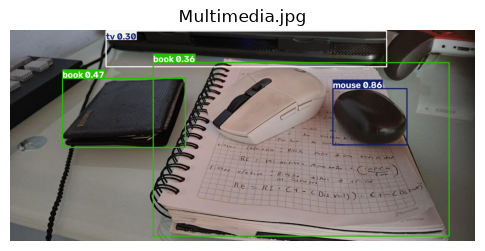

Multimedia (1).jpg 1 detecciones: {'book': 1}


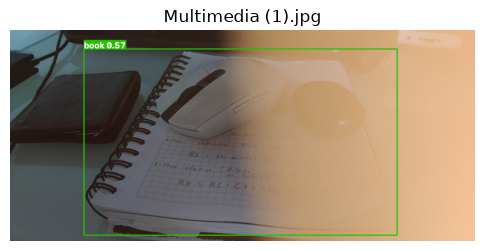

Multimedia (2).jpg 1 detecciones: {'book': 1}


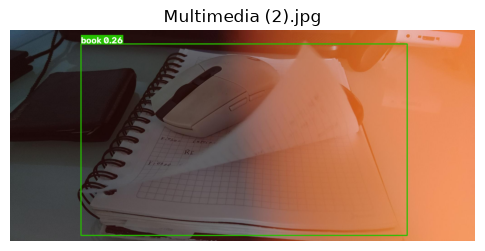

In [12]:
# Celda 10 — Sus propias imágenes (mínimo 3)
# Subir 3 o más fotografías propias al entorno (Colab: panel "Archivos"; local: misma carpeta del notebook).
# Elegir al menos una con objetos MUY juntos (multitud, fila de sillas, pila de cajas) y una en condiciones difíciles
# (poca luz, contraluz, objeto parcialmente tapado).
mis_imagenes = ["Multimedia.jpg", "Multimedia (1).jpg", "Multimedia (2).jpg"] # reemplazar por sus archivos

for ruta in mis_imagenes: 
 n, conteo = resumen(ruta)
 print(f"{ruta:<16} {n} detecciones: {conteo}")
 r = modelo(ruta, verbose=False, device=dispositivo)[0]
 plt.figure(figsize=(6, 5)); plt.imshow(r.plot()[..., ::-1]); plt.axis("off");
 plt.title(ruta); plt.show()


In [13]:
# Celda 11 — Segmentación de instancias: ¿cuánto de la caja ocupa realmente el objeto?
seg = YOLO("yolo11n-seg.pt")
r = seg("bus.jpg", verbose=False, device=dispositivo)[0]

for i, b in enumerate(r.boxes):
 x1, y1, x2, y2 = b.xyxy[0].tolist()
 area_caja = (x2 - x1) * (y2 - y1)
 poly = r.masks.xy[i] # contorno de la máscara, en píxeles de la imagen original

 xs, ys = poly[:, 0], poly[:, 1]
 area_masc = 0.5 * abs(np.dot(xs, np.roll(ys, -1)) - np.dot(ys, np.roll(xs, -1))) 
# fórmula del área de un polígono
 print(f"{seg.names[int(b.cls)]:<10} caja={area_caja:>9,.0f} máscara={area_masc:>9,.0f} máscara/caja={area_masc/area_caja:.2f}")


bus        caja=  402,091 máscara=  260,164 máscara/caja=0.65
person     caja=   67,574 máscara=   21,036 máscara/caja=0.31
person     caja=   96,965 máscara=   49,186 máscara/caja=0.51
person     caja=   56,194 máscara=   34,818 máscara/caja=0.62
stop sign  caja=    2,263 máscara=    1,689 máscara/caja=0.75
person     caja=   23,918 máscara=   10,595 máscara/caja=0.44


In [14]:
# BONO — Fine-tuning de YOLO11n sobre COCO8 (3 épocas, imágenes de 320 px, en CPU tomaun par de minutos)
base = YOLO("yolo11n.pt")
m0 = base.val(data="coco8.yaml", imgsz=320, plots=False, verbose=False,
device=dispositivo)
print(f"Modelo original (320 px): mAP50={m0.box.map50:.3f} mAP50-95={m0.box.map:.3f}")

ajustado = YOLO("yolo11n.pt")
ajustado.train(data="coco8.yaml", epochs=3, imgsz=320, batch=4, workers=0,
device=dispositivo, plots=False, verbose=False)
m1 = ajustado.val(data="coco8.yaml", imgsz=320, plots=False, verbose=False,
device=dispositivo)
print(f"Modelo ajustado (320 px): mAP50={m1.box.map50:.3f} mAP50-95={m1.box.map:.3f}")

Ultralytics 8.4.178  Python-3.14.6 torch-2.14.1+cpu CPU (Intel Core i9-14900HX)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 616.6±320.7 MB/s, size: 54.0 KB)
val: Scanning C:\Users\Rog Strix\OneDrive\Documentos\Universidad\IA\TrabajosFIA\datasets\coco8\labels\val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 1.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 15.0it/s 0.1s
                   all          4         17      0.644      0.567      0.684        0.4
Speed: 0.2ms preprocess, 13.3ms inference, 0.0ms loss, 0.5ms postprocess per image
Modelo original (320 px): mAP50=0.684 mAP50-95=0.400
Ultralytics 8.4.178  Python-3.14.6 torch-2.14.1+cpu CPU (Intel Core i9-14900HX)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False,